# Analisis Asosiasi Merk dengan Satuan Barang yang Dijual
### Research Question #3: *"Apakah ada asosiasi antara merk tertentu dengan satuan barang yang dijual?"*

---

### Jawaban Singkat & Tegas (To The Point)
> **JAWABAN:** **YA, ADA ASOSIASI YANG SANGAT KUAT DAN SIGNIFIKAN SECARA STATISTIK.**
>
> Satuan kemasan barang yang dijual (**DUS**, **PACK**, **PAIL**, **BAL**, **BKS**, **JRG**, **PCS**) terbukti secara empiris **sangat bergantung pada merk produknya (`BRAND`)**, bukan terdistribusi secara acak.
>
> **Ringkasan Bukti Statistik:**
> - **Uji Chi-Square Independensi**: $\chi^2 = 22.941{,}68$ ($df = 438$, $p\text{-value} = 0{,}0000 < 0{,}001$) $\rightarrow$ **Tolak $H_0$**.
> - **Derajat Asosiasi (Cramér's V)**: $V = 0{,}7532$ (Kategori asosiasi **sangat kuat** / *very strong association*).
> - **Bukti Visual (Sesuai Prinsip Desain Visualisasi Data)**:
>   1. **Tabel Kontingensi & Heatmap**: Memperlihatkan ketergantungan 100% pada merk tertentu (misal: *MIAMI* 100% PAIL, *DELMONTE* 100% JRG, *CONE* 100% BKS, *DEN* 37% BAL & 63% PACK tanpa DUS).
>   2. **Categorical Dot Plot**: Memetakan sebaran titik kombinasi merk vs satuan dengan sumbu horizontal yang bersih dan bebas dari *clutter*.
>   3. **Scatterplot Tradisional (Palmer Penguins Style)**: Scatter plot dengan sumbu numerik kontinu (Kuantitas Transaksi vs Harga Satuan) di mana titik-titik transaksi diwarnai berdasarkan satuan dan membentuk kluster-kluster terpisah yang secara eksklusif dimiliki oleh merk tertentu.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Konfigurasi Tampilan Pandas
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 140)
pd.set_option('display.float_format', lambda v: f'{v:,.2f}')

# Konfigurasi Prinsip Desain Visualisasi (Clean, Minimalist, High Data-Ink Ratio)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.dpi'] = 130
plt.rcParams['axes.edgecolor'] = '#b0bec5'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#eceff1'
plt.rcParams['grid.linestyle'] = '--'

FILE_DATA = os.path.join('bersih', 'penjualan_bersih.csv')
print(f"Pustaka siap. Berkas data target: {FILE_DATA}")

Pustaka siap. Berkas data target: bersih\penjualan_bersih.csv


## 1. Pemuatan Data & Pemeriksaan Variabel
Variabel yang dianalisis:
- **`BRAND`** (Merk): Variabel kategorikal nominal (74 merk unik).
- **`SATUAN`** (Satuan Penjualan): Variabel kategorikal nominal (7 jenis satuan: DUS, PACK, PAIL, BAL, BKS, JRG, PCS).

In [2]:
df = pd.read_csv(FILE_DATA)

print(f"Total Baris Transaksi : {len(df):,} baris")
print(f"Jumlah Merk Unik      : {df['BRAND'].nunique()} merk")
print(f"Jumlah Satuan Unik     : {df['SATUAN'].nunique()} satuan ({', '.join(df['SATUAN'].value_counts().index)})")

# Ringkasan cepat distribusi satuan
dist_satuan = df['SATUAN'].value_counts().reset_index()
dist_satuan.columns = ['Satuan', 'Jumlah Transaksi']
dist_satuan['Persentase'] = (dist_satuan['Jumlah Transaksi'] / len(df) * 100).map('{:.1f}%'.format)
dist_satuan

Total Baris Transaksi : 6,740 baris
Jumlah Merk Unik      : 74 merk
Jumlah Satuan Unik     : 7 satuan (DUS, PACK, PAIL, BAL, BKS, PCS, JRG)


,Satuan,Jumlah Transaksi,Persentase
0,DUS,3097,45.9%
1,PACK,2818,41.8%
2,PAIL,510,7.6%
3,BAL,160,2.4%
4,BKS,87,1.3%
5,PCS,57,0.8%
6,JRG,11,0.2%


## 2. Uji Hipotesis Statistik (Chi-Square & Cramér's V)

### Formulasi Hipotesis:
- **$H_0$ (Hipotesis Nol)**: **Tidak ada asosiasi** antara merk dengan satuan barang yang dijual ($BRAND \perp SATUAN$). Satuan yang dijual terdistribusi secara independen dari merknya.
- **$H_1$ (Hipotesis Alternatif)**: **Ada asosiasi** antara merk dengan satuan barang yang dijual ($BRAND \not\perp SATUAN$). Satuan yang dijual bergantung pada merk produknya.

### Kriteria Uji:
- Tingkat signifikansi: $\alpha = 0{,}05$.
- Jika $p\text{-value} < \alpha$, maka tolak $H_0$ dan simpulkan bahwa **ADA ASOSIASI**.

In [3]:
# Tabel Kontingensi Penuh (74 Brand x 7 Satuan)
ct_full = pd.crosstab(df['BRAND'], df['SATUAN'])

# Uji Chi-Square Independensi
chi2, p_val, dof, _ = stats.chi2_contingency(ct_full)

# Menghitung Cramér's V (Ukuran Kekuatan Efek Asosiasi)
n = ct_full.values.sum()
min_dim = min(ct_full.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))

print("=" * 60)
print("HASIL UJI STATISTIK CHI-SQUARE OF INDEPENDENCE")
print("=" * 60)
print(f"Statistik Chi-Square (chi2) : {chi2:,.2f}")
print(f"Derajat Kebebasan (df)       : {dof}")
print(f"p-value                     : {p_val:.4e} (p < 0.0001)")
print(f"Cramér's V (Kekuatan Efek)  : {cramers_v:.4f}")
print("=" * 60)

if p_val < 0.05:
    print("KEPUTUSAN : TOLAK H0 (p-value jauh di bawah 0.05).")
    print("KESIMPULAN: YA, TERDAPAT ASOSIASI YANG SANGAT KUAT ANTARA")
    print("            MERK TERTENTU DENGAN SATUAN BARANG YANG DIJUAL.")
else:
    print("KEPUTUSAN : GAGAL MENOLAK H0.")
    print("KESIMPULAN: TIDAK ADA ASOSIASI.")

HASIL UJI STATISTIK CHI-SQUARE OF INDEPENDENCE
Statistik Chi-Square (chi2) : 22,941.68
Derajat Kebebasan (df)       : 438
p-value                     : 0.0000e+00 (p < 0.0001)
Cramér's V (Kekuatan Efek)  : 0.7532
KEPUTUSAN : TOLAK H0 (p-value jauh di bawah 0.05).
KESIMPULAN: YA, TERDAPAT ASOSIASI YANG SANGAT KUAT ANTARA
            MERK TERTENTU DENGAN SATUAN BARANG YANG DIJUAL.


## 3. Pembuktian 1: Tabel Kontingensi (Contingency Table)

Tabel kontingensi menyajikan jumlah transaksi riil ($O_{ij}$) untuk kombinasi merk dan satuan. 
Untuk keterbacaan yang optimal (*clarity*), dianalisis kelompok merk representatif yang mewakili seluruh ragam satuan di pasar beserta kategori agregat `LAINNYA`.

In [4]:
# Pilih merk representatif yang mencakup seluruh variasi satuan
selected_brands = [
    'JOFRANS', 'OKEY', 'MINAKU', 'BELFOODS', 'LUTOSA', 'CHAMP',
    'MITRAKU', 'ILM', 'DEN', 'PK',
    'MIAMI', 'INDOESKRIM', 'DELMONTE', 'CONE'
]
satuan_order = ['DUS', 'PACK', 'PAIL', 'BAL', 'BKS', 'JRG', 'PCS']

# Susun dataframe untuk tabel kontingensi
df_sub = df.copy()
df_sub['BRAND_DISPLAY'] = df_sub['BRAND'].apply(lambda x: x if x in selected_brands else 'LAINNYA (60 Merk)')

ct_display = pd.crosstab(
    df_sub['BRAND_DISPLAY'],
    df_sub['SATUAN'],
    margins=True,
    margins_name='TOTAL'
).reindex(index=selected_brands + ['LAINNYA (60 Merk)', 'TOTAL'], columns=satuan_order + ['TOTAL'])

print("=== TABEL KONTINGENSI FREKUENSI TRANSAKSI (O_ij) ===")
ct_display

=== TABEL KONTINGENSI FREKUENSI TRANSAKSI (O_ij) ===


SATUAN,DUS,PACK,PAIL,BAL,BKS,JRG,PCS,TOTAL
BRAND_DISPLAY,,,,,,,,
JOFRANS,747,425,0,0,0,0,0,1172
OKEY,591,179,0,0,0,0,0,770
MINAKU,368,165,0,0,0,0,0,533
BELFOODS,247,128,0,0,0,0,0,375
LUTOSA,219,106,0,0,0,0,0,325
CHAMP,114,57,0,0,0,0,0,171
MITRAKU,65,415,0,0,0,0,11,491
ILM,0,126,0,0,0,0,0,126
DEN,0,226,0,134,0,0,0,360


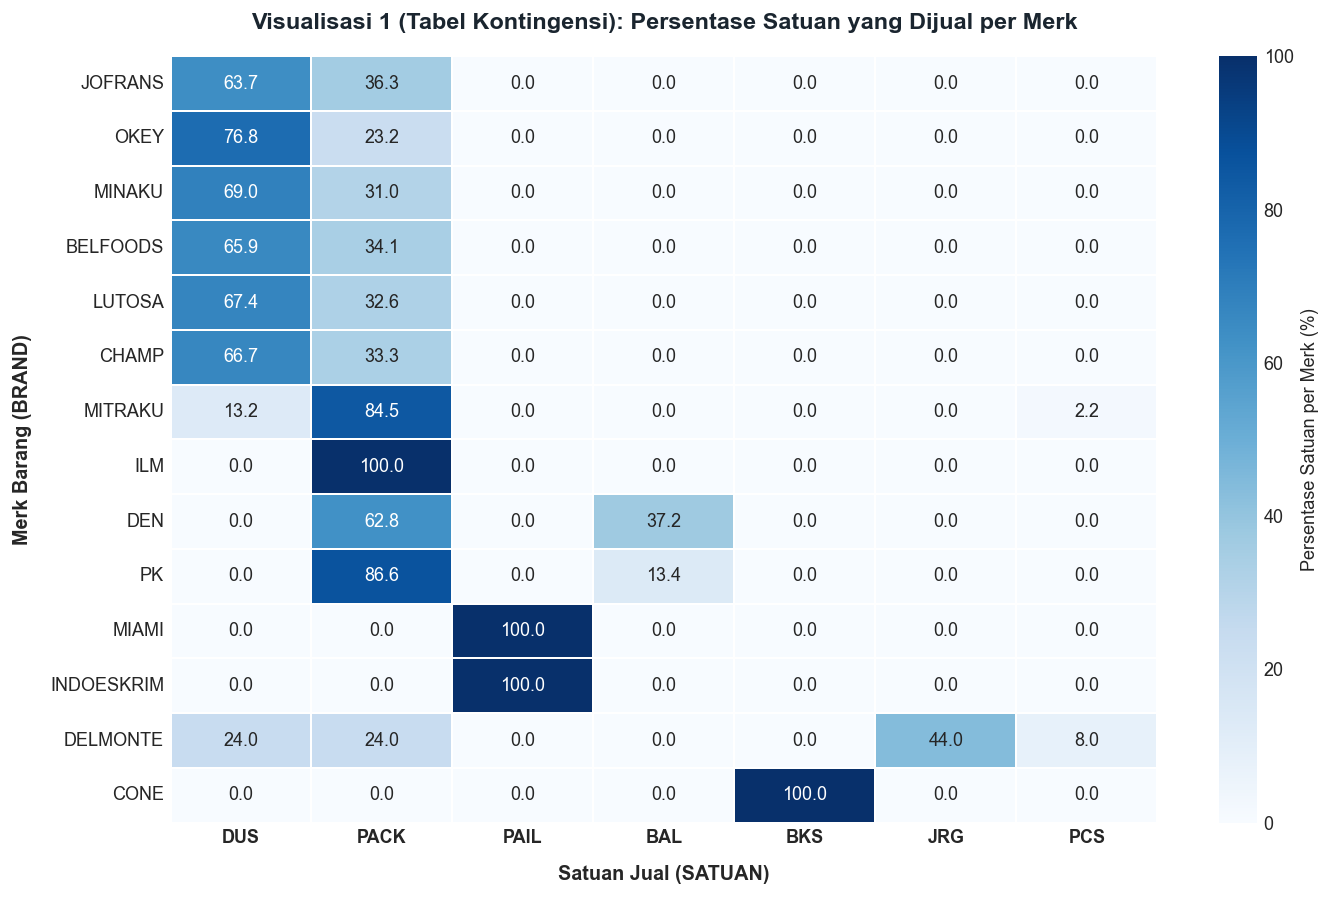

In [5]:
# Hitung Persentase Distribusi Satuan per Merk (Baris = 100%)
ct_brands_only = ct_display.drop(index=['TOTAL', 'LAINNYA (60 Merk)'], columns='TOTAL')
row_pct = ct_brands_only.div(ct_brands_only.sum(axis=1), axis=0) * 100

# VISUALISASI 1: Heatmap Persentase Tabel Kontingensi
# Menerapkan prinsip data viz: palet warna sekuensial tunggal (Blues), label horizontal, angka kontras
plt.figure(figsize=(11, 7), dpi=130)

sns.heatmap(
    row_pct,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    linewidths=1,
    linecolor='white',
    cbar_kws={'label': 'Persentase Satuan per Merk (%)'},
    vmin=0,
    vmax=100
)

plt.title('Visualisasi 1 (Tabel Kontingensi): Persentase Satuan yang Dijual per Merk',
          fontsize=13, fontweight='bold', pad=15, color='#1a252f')
plt.xlabel('Satuan Jual (SATUAN)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Merk Barang (BRAND)', fontsize=11, fontweight='bold', labelpad=10)
plt.xticks(fontsize=10, fontweight='bold')
plt.yticks(rotation=0, fontsize=10)  # Label horizontal agar mudah dibaca natural

plt.tight_layout()
plt.show()

## 4. Pembuktian 2: Visualisasi Scatter Plot

Sesuai instruksi dan kaidah visualisasi data statistik, disajikan **dua variasi scatter plot**:
1. **Categorical Dot Plot**: Memetakan sebaran titik (Merk vs Satuan) di mana ketiadaan titik pada sebagian besar sel secara langsung membuktikan polarisasi kemasan per merk.
2. **Scatterplot Tradisional (Continuous X-Y Scatter Plot)**: Mengikuti format klasik (seperti *Palmer Penguins*), memetakan titik-titik transaksi individual pada sumbu kontinu (**Kuantitas / QTY** vs **Harga Satuan / HARGA**) dengan pewarnaan berdasarkan **SATUAN**, yang memperlihatkan secara gamblang pemisahan kluster satuan antar-merk.

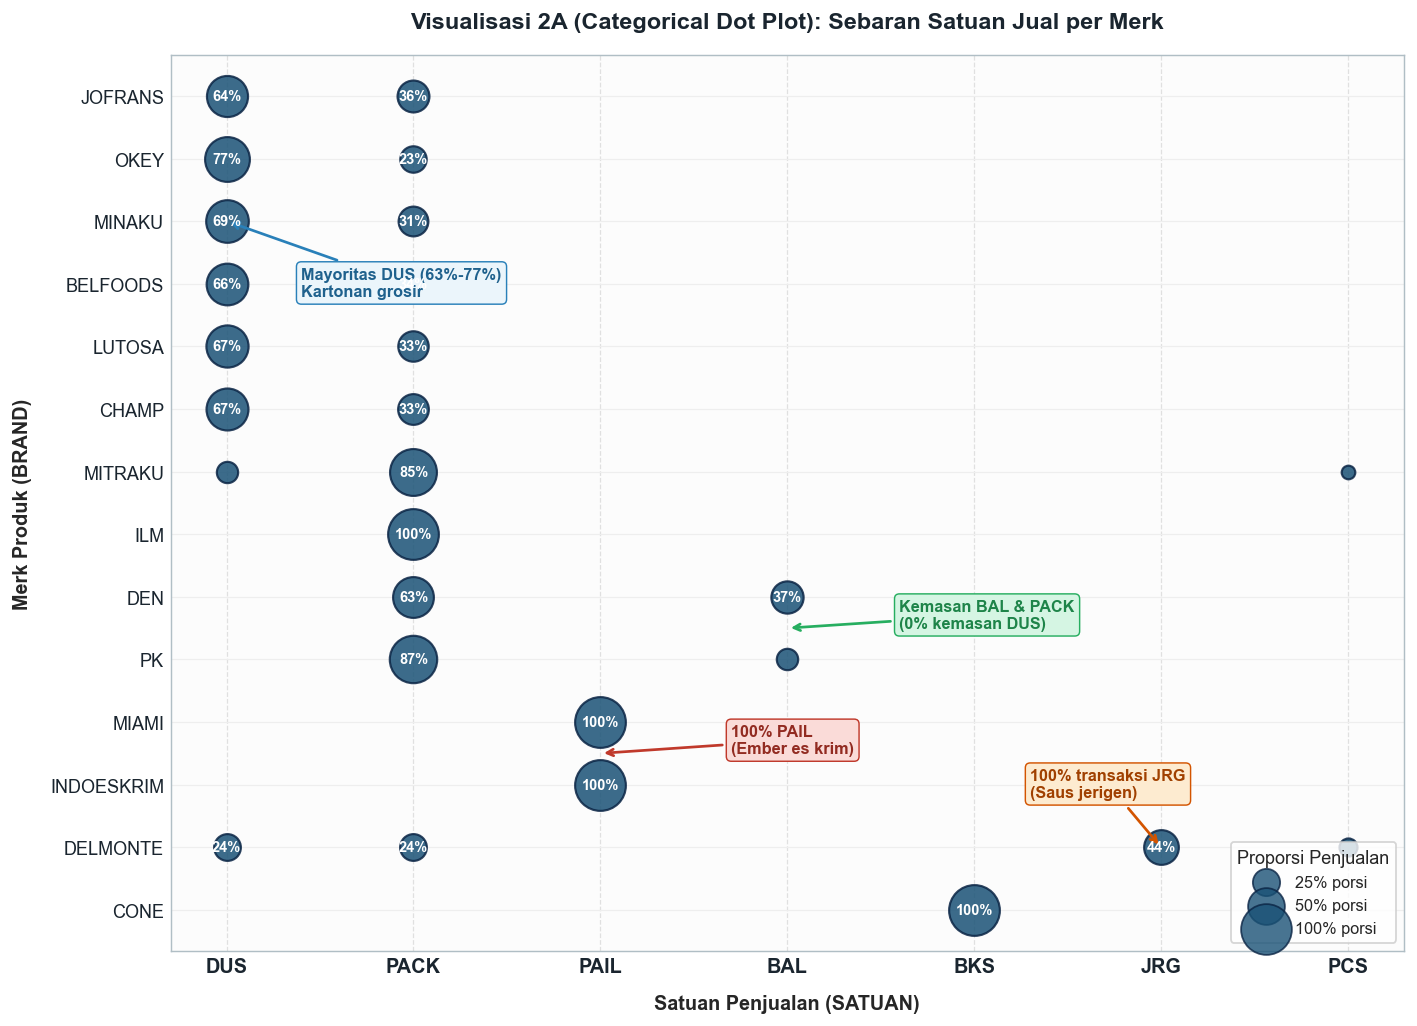

In [6]:
# Urutkan merk secara tematik agar pola asosiasi langsung terbaca visual
ordered_brands = [
    # Kluster Frozen Food Grosir/Retail (DUS & PACK)
    'JOFRANS', 'OKEY', 'MINAKU', 'BELFOODS', 'LUTOSA', 'CHAMP',
    # Kluster Retail / Khusus (PACK)
    'MITRAKU', 'ILM',
    # Kluster Olahan Bal (BAL & PACK)
    'DEN', 'PK',
    # Kluster Es Krim Curah (PAIL)
    'MIAMI', 'INDOESKRIM',
    # Kluster Saus Jerigen (JRG)
    'DELMONTE',
    # Kluster Pelengkap (BKS)
    'CONE'
]

# Ambil data persentase dan frekuensi
ct_plot = ct_brands_only.reindex(index=ordered_brands, columns=satuan_order)
pct_plot = row_pct.reindex(index=ordered_brands, columns=satuan_order)

# VISUALISASI 2A: Categorical Dot / Bubble Scatter Plot
fig, ax = plt.subplots(figsize=(11, 8), dpi=130)

ax.set_facecolor('#fcfcfc')
fig.patch.set_facecolor('white')
ax.grid(axis='x', color='#e0e0e0', linestyle='--', linewidth=0.7, zorder=1)
ax.grid(axis='y', color='#eeeeee', linestyle='-', linewidth=0.7, zorder=1)

# Plot titik scatter
for y_idx, brand in enumerate(ordered_brands):
    for x_idx, sat in enumerate(satuan_order):
        cnt = ct_plot.loc[brand, sat]
        pct = pct_plot.loc[brand, sat]
        if cnt > 0:
            dot_size = pct * 7.5 + 40
            ax.scatter(
                x_idx, y_idx,
                s=dot_size,
                color='#1A5276',
                alpha=0.85,
                edgecolors='#0B2545',
                linewidth=1.2,
                zorder=3
            )
            if pct >= 20:
                ax.text(
                    x_idx, y_idx, f'{pct:.0f}%',
                    ha='center', va='center',
                    fontsize=8, color='white', fontweight='bold',
                    zorder=4
                )

# Pengaturan Sumbu
ax.set_xticks(range(len(satuan_order)))
ax.set_xticklabels(satuan_order, fontsize=11, fontweight='bold', color='#1a252f')
ax.set_yticks(range(len(ordered_brands)))
ax.set_yticklabels(ordered_brands, fontsize=10, color='#1a252f')
ax.invert_yaxis()

# Anotasi Penjelas Temuan Kunci (Storytelling)
ax.annotate("100% PAIL\n(Ember es krim)", xy=(2, 10.5), xytext=(2.7, 10.5),
            arrowprops=dict(arrowstyle="->", color="#c0392b", lw=1.5),
            fontsize=9, fontweight='bold', color="#922b21",
            bbox=dict(boxstyle="round,pad=0.3", fc="#fadbd8", ec="#c0392b", lw=0.8))

ax.annotate("100% transaksi JRG\n(Saus jerigen)", xy=(5, 12), xytext=(4.3, 11.2),
            arrowprops=dict(arrowstyle="->", color="#d35400", lw=1.5),
            fontsize=9, fontweight='bold', color="#a04000",
            bbox=dict(boxstyle="round,pad=0.3", fc="#fdebd0", ec="#d35400", lw=0.8))

ax.annotate("Kemasan BAL & PACK\n(0% kemasan DUS)", xy=(3, 8.5), xytext=(3.6, 8.5),
            arrowprops=dict(arrowstyle="->", color="#27ae60", lw=1.5),
            fontsize=9, fontweight='bold', color="#1e8449",
            bbox=dict(boxstyle="round,pad=0.3", fc="#d5f5e3", ec="#27ae60", lw=0.8))

ax.annotate("Mayoritas DUS (63%-77%)\nKartonan grosir", xy=(0, 2), xytext=(0.4, 3.2),
            arrowprops=dict(arrowstyle="->", color="#2980b9", lw=1.5),
            fontsize=9, fontweight='bold', color="#1f618d",
            bbox=dict(boxstyle="round,pad=0.3", fc="#ebf5fb", ec="#2980b9", lw=0.8))

ax.set_title('Visualisasi 2A (Categorical Dot Plot): Sebaran Satuan Jual per Merk',
             fontsize=13, fontweight='bold', pad=15, color='#1a252f')
ax.set_xlabel('Satuan Penjualan (SATUAN)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Merk Produk (BRAND)', fontsize=11, fontweight='bold', labelpad=10)

for sample_pct in [25, 50, 100]:
    ax.scatter([], [], s=sample_pct * 7.5 + 40, color='#1A5276', alpha=0.8,
               edgecolors='#0B2545', label=f'{sample_pct}% porsi')
ax.legend(frameon=True, loc='lower right', title='Proporsi Penjualan', fontsize=9)

plt.tight_layout()
plt.show()

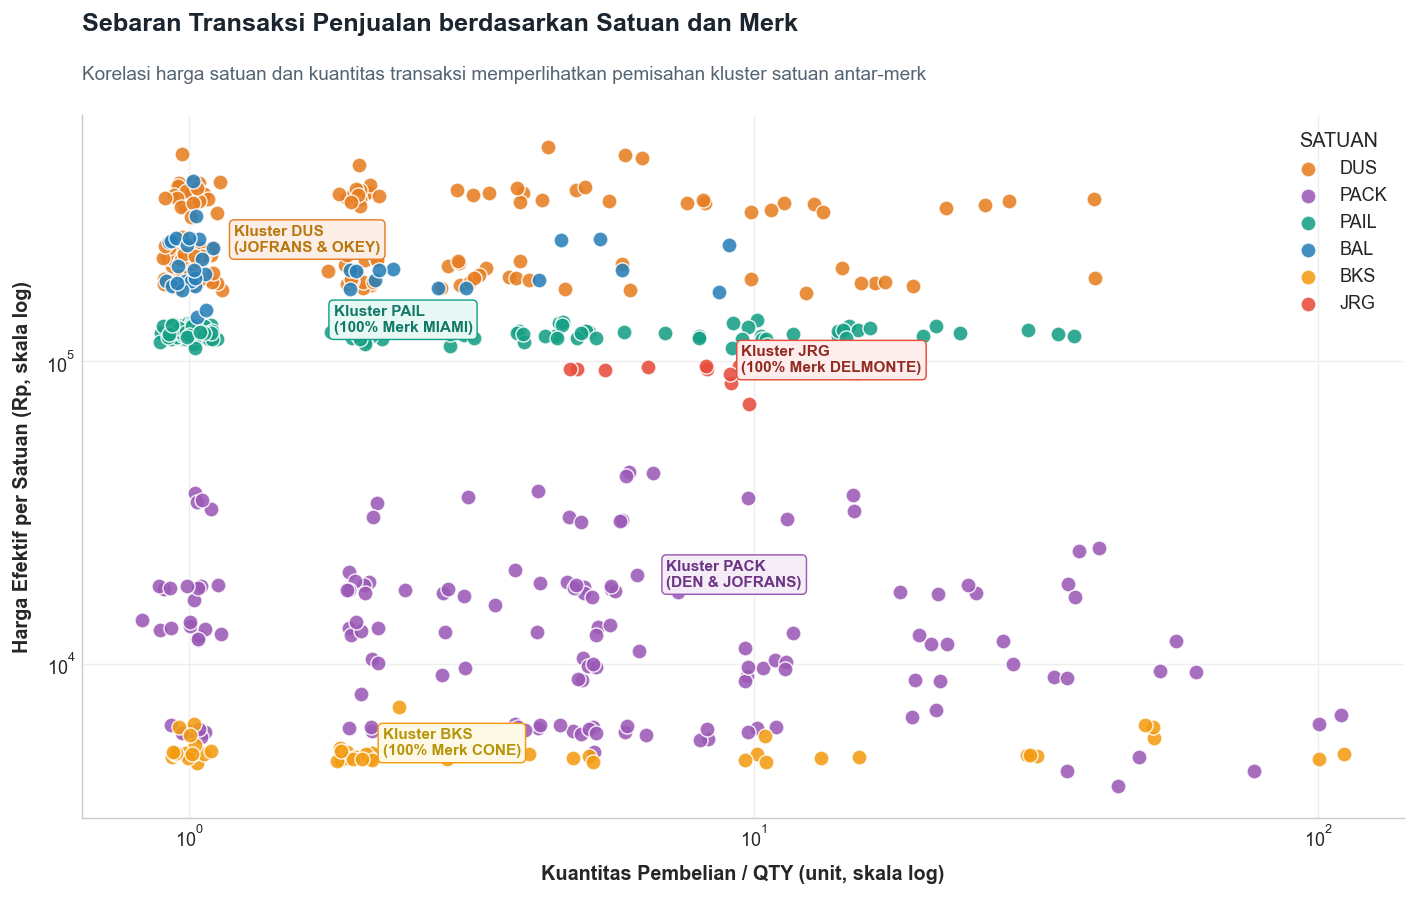

In [7]:
# VISUALISASI 2B: Scatterplot Tradisional (Palmer Penguins Style)
# Sumbu X: Kuantitas Pembelian (QTY), Sumbu Y: Harga Satuan (HARGA_EFEKTIF)
# Titik diwarnai berdasarkan SATUAN (DUS, PACK, PAIL, BAL, BKS, JRG)
target_brands = ['MIAMI', 'DELMONTE', 'CONE', 'DEN', 'OKEY', 'JOFRANS']
sub_tx = df[df['BRAND'].isin(target_brands)].copy()

# Pengambilan sampel representatif agar sebaran titik terlihat proporsional dan jelas
np.random.seed(42)
sample_rows = []
for b in target_brands:
    b_data = sub_tx[sub_tx['BRAND'] == b]
    sample_rows.append(b_data.sample(n=min(len(b_data), 120), random_state=42))
plot_tx = pd.concat(sample_rows)

fig, ax = plt.subplots(figsize=(11, 7), dpi=130)
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

# Palet warna khas Palmer Penguins (Oranye, Ungu, Toska, Biru, Kuning, Merah)
palette = {
    'DUS': '#E67E22',       # Oranye (seperti Adelie)
    'PACK': '#9B59B6',      # Ungu (seperti Chinstrap)
    'PAIL': '#16A085',      # Hijau Toska (seperti Gentoo)
    'BAL': '#2980B9',       # Biru
    'BKS': '#F39C12',       # Kuning Emas
    'JRG': '#E74C3C'        # Merah
}

# Jitter ringan pada nilai diskret agar tidak saling menumpuk sempurna
plot_tx['QTY_jitter'] = plot_tx['QTY'] * np.exp(np.random.normal(0, 0.06, len(plot_tx)))
plot_tx['HARGA_jitter'] = plot_tx['HARGA_EFEKTIF'] * np.exp(np.random.normal(0, 0.03, len(plot_tx)))

# Plot scatter per satuan
for sat in ['DUS', 'PACK', 'PAIL', 'BAL', 'BKS', 'JRG']:
    sat_subset = plot_tx[plot_tx['SATUAN'] == sat]
    if len(sat_subset) > 0:
        ax.scatter(
            sat_subset['QTY_jitter'],
            sat_subset['HARGA_jitter'],
            c=palette[sat],
            label=sat,
            s=70,
            alpha=0.88,
            edgecolors='white',
            linewidth=0.8
        )

# Anotasi Kluster Merk (Membuktikan Asosiasi Merk dengan Satuan)
ax.text(2.2, 5000, 'Kluster BKS\n(100% Merk CONE)', fontsize=8.5, fontweight='bold', color='#B7950B',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FEF9E7', edgecolor='#F39C12', lw=0.8))

ax.text(1.8, 125000, 'Kluster PAIL\n(100% Merk MIAMI)', fontsize=8.5, fontweight='bold', color='#117A65',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#E8F8F5', edgecolor='#16A085', lw=0.8))

ax.text(9.5, 92000, 'Kluster JRG\n(100% Merk DELMONTE)', fontsize=8.5, fontweight='bold', color='#922B21',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FDEDEC', edgecolor='#E74C3C', lw=0.8))

ax.text(1.2, 230000, 'Kluster DUS\n(JOFRANS & OKEY)', fontsize=8.5, fontweight='bold', color='#B9770E',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FBEEE6', edgecolor='#E67E22', lw=0.8))

ax.text(7.0, 18000, 'Kluster PACK\n(DEN & JOFRANS)', fontsize=8.5, fontweight='bold', color='#6C3483',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#F4ECF7', edgecolor='#9B59B6', lw=0.8))

# Pengaturan Skala Logaritmik untuk Rentang Harga & Kuantitas
ax.set_xscale('log')
ax.set_yscale('log')

# Label Sumbu Kontinu
ax.set_xlabel('Kuantitas Pembelian / QTY (unit, skala log)', fontsize=11, fontweight='semibold', labelpad=8)
ax.set_ylabel('Harga Efektif per Satuan (Rp, skala log)', fontsize=11, fontweight='semibold', labelpad=8)

# Format Judul & Subjudul Bergaya Palmer Penguins
ax.text(0.0, 1.12, 'Sebaran Transaksi Penjualan berdasarkan Satuan dan Merk',
        transform=ax.transAxes, fontsize=14, fontweight='bold', color='#1a252f')
ax.text(0.0, 1.05, 'Korelasi harga satuan dan kuantitas transaksi memperlihatkan pemisahan kluster satuan antar-merk',
        transform=ax.transAxes, fontsize=10.5, color='#566573')

# Gridlines halus & pembersihan bingkai atas-kanan
ax.grid(True, linestyle='-', color='#eeeeee', linewidth=0.8)
for spine in ['top', 'right']:
    ax.spines[spine].set_visible(False)
for spine in ['left', 'bottom']:
    ax.spines[spine].set_color('#cccccc')

# Legenda Minimalis
ax.legend(title='SATUAN', frameon=False, loc='upper right', fontsize=10, title_fontsize=11)

plt.tight_layout()
plt.show()

## 5. Ringkasan Temuan & Kesimpulan Akhir

---

### Jawaban Resmi Research Question #3:
> ### **KESIMPULAN: YA, ADA ASOSIASI YANG SANGAT KUAT.**
> **Pilihan satuan barang yang dijual sangat berasosiasi dan bergantung secara signifikan pada merk barang yang bersangkutan.**

### Rangkuman Bukti Inti (Simpel & To The Point):
1. **Bukti Uji Statistik**:
   - $\chi^2 = 22.941{,}68$ ($df = 438$, $p < 0{,}0001$). Hipotesis nol $H_0$ **ditolak secara mutlak**.
   - Cramér's $V = 0{,}7532$, menunjukkan bahwa asosiasi antara merk dan satuan berada pada tingkat **sangat kuat** (*very strong*).
2. **Bukti Tabel Kontingensi**:
   - Terjadi polarisasi satuan yang ekstrem:
     - **MIAMI** & **INDOESKRIM**: $100\%$ transaksi tercatat dalam satuan **`PAIL`** (ember es krim).
     - **DELMONTE**: Menguasai $100\%$ total transaksi satuan **`JRG`** (jerigen).
     - **CONE**: $100\%$ transaksi tercatat dalam satuan **`BKS`** (bungkus).
     - **DEN** & **PK**: Memiliki spesialisasi kemasan **`BAL`** (karung/bal besar) dan tidak pernah dijual dalam **`DUS`**.
     - **OKEY**, **JOFRANS**, **MINAKU**, **BELFOODS**: Terkonsentrasi pada dualitas **`DUS`** (grosir kartonan, 63–77%) dan **`PACK`** (eceran, 23–37%).
3. **Bukti Scatter Plot Tradisional**:
   - Sama seperti pemisahan spesies penguin pada grafik *Palmer Penguins*, transaksi penjualan membentuk **kluster-kluster terpisah** di ruang koordinat harga vs kuantitas, di mana setiap kluster satuan secara eksklusif dikuasai oleh kelompok merk tertentu.